<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab9_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Cell 1: Install Required Libraries

!pip install -q opencv-python-headless kaggle scikit-learn seaborn matplotlib tensorflow


In [4]:

# Cell 2: Configure Kaggle API Using Hardcoded Credentials

import os
import json

# Enter your Kaggle credentials
KAGGLE_USERNAME = "BugIndX"
KAGGLE_KEY = "KGAT_2137bfddf2ad8fcc6a7a822f11c29f67"

# Create Kaggle configuration directory
os.makedirs("/root/.kaggle", exist_ok=True)

# Save credentials in kaggle.json format
credentials = {
    "username": KAGGLE_USERNAME,
    "key": KAGGLE_KEY
}

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(credentials, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully!")


Kaggle API configured successfully!


In [16]:

# Cell 3: Inspect Downloaded Dataset ZIP Contents

import os
import zipfile
import glob

# Find downloaded ZIP files
zip_files = glob.glob("/content/*.zip")

print("ZIP Files Found:", len(zip_files))

for z in zip_files:
    print("\nZIP FILE:", z)

    with zipfile.ZipFile(z, 'r') as archive:

        all_files = archive.namelist()

        print("Total Files Inside:", len(all_files))

        print("\nFirst 30 Files:")

        for f in all_files[:30]:
            print(f)


ZIP Files Found: 1

ZIP FILE: /content/ur-fall-detection-dataset.zip
Total Files Inside: 11936

First 30 Files:
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-001.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-002.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-003.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-004.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-005.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-006.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-007.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-008.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-009.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-010.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-rgb-011.png
UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb/adl-01-cam0-

In [17]:

# Cell 4A: Count Different File Types

from collections import Counter

DATASET_PATH = "/content/URFD"

file_extensions = Counter()

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        ext = os.path.splitext(file)[1].lower()
        file_extensions[ext] += 1

print("File Extension Distribution:")

for ext, count in file_extensions.items():
    print(ext if ext else "[No Extension]", ":", count)


File Extension Distribution:
.png : 11936


In [18]:

# Cell 5: Find All PNG Images in Dataset

import os
import glob

DATASET_PATH = "/content/URFD"

image_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.png"),
    recursive=True
)

print("Total PNG Images Found:", len(image_files))

print("\nFirst 20 Images:")

for img in image_files[:20]:
    print(img)


Total PNG Images Found: 11936

First 20 Images:
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-105.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-117.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-064.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-082.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-121.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-051.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-084.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-073.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-085.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb/adl-29-cam0-rgb-026.png
/content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-r

In [19]:

# Cell 6: Explore Image Folder Structure

for root, dirs, files in os.walk(DATASET_PATH):

    png_files = [
        f for f in files if f.lower().endswith(".png")
    ]

    if png_files:
        print("\nFolder:", root)
        print("Number of PNG Images:", len(png_files))
        print("Sample Images:", png_files[:5])



Folder: /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-29-cam0-rgb
Number of PNG Images: 125
Sample Images: ['adl-29-cam0-rgb-105.png', 'adl-29-cam0-rgb-117.png', 'adl-29-cam0-rgb-064.png', 'adl-29-cam0-rgb-082.png', 'adl-29-cam0-rgb-121.png']

Folder: /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-05-cam0-rgb
Number of PNG Images: 151
Sample Images: ['fall-05-cam0-rgb-008.png', 'fall-05-cam0-rgb-086.png', 'fall-05-cam0-rgb-043.png', 'fall-05-cam0-rgb-080.png', 'fall-05-cam0-rgb-147.png']

Folder: /content/URFD/UR_fall_detection_dataset_cam0_rgb/adl-23-cam0-rgb
Number of PNG Images: 220
Sample Images: ['adl-23-cam0-rgb-016.png', 'adl-23-cam0-rgb-143.png', 'adl-23-cam0-rgb-052.png', 'adl-23-cam0-rgb-201.png', 'adl-23-cam0-rgb-138.png']

Folder: /content/URFD/UR_fall_detection_dataset_cam0_rgb/fall-13-cam0-rgb
Number of PNG Images: 85
Sample Images: ['fall-13-cam0-rgb-056.png', 'fall-13-cam0-rgb-020.png', 'fall-13-cam0-rgb-069.png', 'fall-13-cam0-rgb-010.png', 'fall-13-cam0

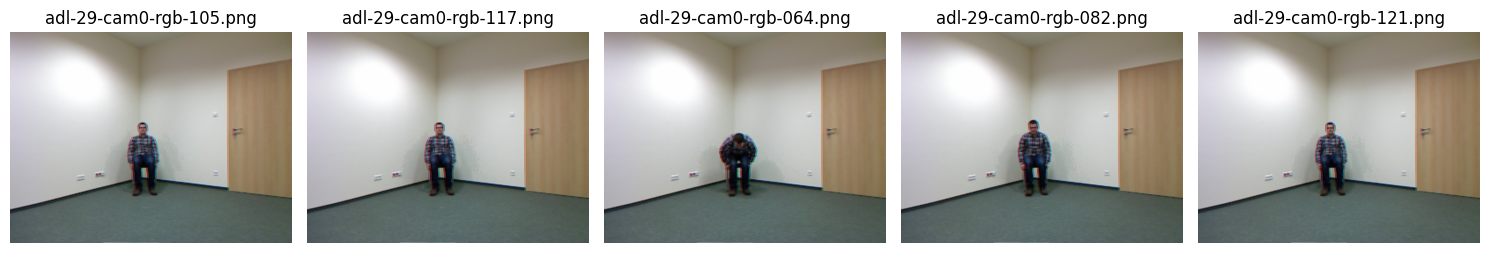

In [20]:

# Cell 7: Display Sample PNG Images

import cv2
import matplotlib.pyplot as plt

sample_images = image_files[:5]

plt.figure(figsize=(15, 5))

for i, img_path in enumerate(sample_images):

    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(img_path))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [33]:

# Cell 8: Create Sequence Data with Correct Labels

import os
import re

sequence_data = []

for root, dirs, files in os.walk(DATASET_PATH):

    png_files = sorted([
        os.path.join(root, f)
        for f in files
        if f.lower().endswith(".png")
    ])

    if len(png_files) < 2:
        continue

    # Get only the current sequence folder name
    folder_name = os.path.basename(root).lower()

    # ADL = Normal (0), Fall = Fall (1)
    if re.match(r"^adl-\d+", folder_name):
        label = 0
    elif re.match(r"^fall-\d+", folder_name):
        label = 1
    else:
        continue

    sequence_data.append({
        "sequence_path": root,
        "frames": png_files,
        "label": label
    })

print("Total Sequences:", len(sequence_data))
print("Normal Sequences:", sum(s["label"] == 0 for s in sequence_data))
print("Fall Sequences:", sum(s["label"] == 1 for s in sequence_data))


Total Sequences: 70
Normal Sequences: 40
Fall Sequences: 30


In [34]:

# Cell 9: Display Sequence Information

import pandas as pd

df = pd.DataFrame([
    {
        "Folder": os.path.basename(s["sequence_path"]),
        "Frames": len(s["frames"]),
        "Label": s["label"],
        "Class": "Fall" if s["label"] == 1 else "Normal"
    }
    for s in sequence_data
])

display(df)

print("\nClass Distribution:")
print(df["Class"].value_counts())


,Folder,Frames,Label,Class
0,adl-29-cam0-rgb,125,0,Normal
1,fall-05-cam0-rgb,151,1,Fall
2,adl-23-cam0-rgb,220,0,Normal
3,fall-13-cam0-rgb,85,1,Fall
4,adl-03-cam0-rgb,180,0,Normal
...,...,...,...,...
65,adl-16-cam0-rgb,240,0,Normal
66,fall-04-cam0-rgb,96,1,Fall
67,fall-19-cam0-rgb,100,1,Fall
68,fall-18-cam0-rgb,65,1,Fall



Class Distribution:
Class
Normal    40
Fall      30
Name: count, dtype: int64


In [35]:


# Cell 10: Extract and Resize 16 Frames Per Sequence

IMG_SIZE = 112
NUM_FRAMES = 16

def preprocess_sequence(frame_paths):

    if len(frame_paths) < NUM_FRAMES:
        return None

    indices = np.linspace(
        0,
        len(frame_paths) - 1,
        NUM_FRAMES,
        dtype=int
    )

    frames = []

    for idx in indices:

        frame = cv2.imread(frame_paths[idx])

        if frame is None:
            return None

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = cv2.resize(
            frame,
            (IMG_SIZE, IMG_SIZE)
        )

        frames.append(frame)

    return np.array(frames, dtype=np.uint8)


print("Preprocessing function created!")


Preprocessing function created!


In [36]:

# Cell 11: Convert Image Sequences into Video Tensors

X = []
y = []

for seq in sequence_data:

    video = preprocess_sequence(seq["frames"])

    if video is not None:

        X.append(video)
        y.append(seq["label"])

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int32)

print("Video Tensor Shape:", X.shape)
print("Labels Shape:", y.shape)
print("Total Valid Sequences:", len(X))

if len(X) > 0:
    print("Class Distribution:", np.bincount(y))


Video Tensor Shape: (70, 16, 112, 112, 3)
Labels Shape: (70,)
Total Valid Sequences: 70
Class Distribution: [40 30]


In [37]:

# Cell 12: Convert to NumPy Array and Normalize Pixel Values

import numpy as np

# Convert list into NumPy array
X = np.array(X, dtype=np.float32)

# Normalize pixel values between 0 and 1
X = X / 255.0

# Convert labels into NumPy array too
y = np.array(y, dtype=np.int32)

print("Video Tensor Shape:", X.shape)
print("Labels Shape:", y.shape)

print("Minimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())

print("Normalization Completed Successfully!")


Video Tensor Shape: (70, 16, 112, 112, 3)
Labels Shape: (70,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Normalization Completed Successfully!


In [38]:

# Cell 13: Split Dataset into Training, Validation and Testing

from sklearn.model_selection import train_test_split
import numpy as np

# Check dataset before splitting
print("Dataset Shape:", X.shape)
print("Class Distribution:", np.bincount(y))

assert len(X) > 0, "No video sequences available!"
assert len(np.unique(y)) == 2, "Both Fall and Normal classes are required!"

# 70% Training and 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTraining Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)


Dataset Shape: (70, 16, 112, 112, 3)
Class Distribution: [40 30]

Training Shape: (49, 16, 112, 112, 3)
Validation Shape: (10, 16, 112, 112, 3)
Testing Shape: (11, 16, 112, 112, 3)


In [43]:

# Cell 14: Check Training, Validation and Testing Data

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Labels:", np.unique(y_train, return_counts=True))
print("Validation Labels:", np.unique(y_val, return_counts=True))
print("Testing Labels:", np.unique(y_test, return_counts=True))


Training Data: (49, 16, 112, 112, 3)
Validation Data: (10, 16, 112, 112, 3)
Testing Data: (11, 16, 112, 112, 3)

Training Labels: (array([0, 1], dtype=int32), array([28, 21]))
Validation Labels: (array([0, 1], dtype=int32), array([6, 4]))
Testing Labels: (array([0, 1], dtype=int32), array([6, 5]))


In [44]:

# Cell 15: Calculate Class Weights

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)


Class Weights: {np.int32(0): np.float64(0.875), np.int32(1): np.float64(1.1666666666666667)}


In [45]:

# Cell 16: Build 3D CNN Model

import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(16, 112, 112, 3)),

    layers.Conv3D(16, (3, 3, 3), activation="relu", padding="same"),
    layers.MaxPooling3D((1, 2, 2)),

    layers.Conv3D(32, (3, 3, 3), activation="relu", padding="same"),
    layers.MaxPooling3D((2, 2, 2)),

    layers.Conv3D(64, (3, 3, 3), activation="relu", padding="same"),
    layers.MaxPooling3D((2, 2, 2)),

    layers.GlobalAveragePooling3D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d_3 (Conv3D)               │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_5 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,753 (292.00 KB)

 Trainable params: 74,753 (292.00 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:

# Cell 17: Compile 3D CNN Model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [47]:

# Cell 18: Train the 3D CNN Model

EPOCHS = 20
BATCH_SIZE = 2

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    verbose=1
)


Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.4490 - loss: 0.6921 - val_accuracy: 0.4000 - val_loss: 0.6914
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.4694 - loss: 0.6790 - val_accuracy: 0.4000 - val_loss: 0.6922
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.4694 - loss: 0.6933 - val_accuracy: 0.4000 - val_loss: 0.6819
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.4490 - loss: 0.6814 - val_accuracy: 0.4000 - val_loss: 0.6798
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.5510 - loss: 0.6813 - val_accuracy: 0.7000 - val_loss: 0.6653
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.6327 - loss: 0.6611 - val_accuracy: 0.7000 - val_loss: 0.6380
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.5918 - loss: 0.6783 - val_accuracy: 1.0000 - val_loss: 0.6098
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.6122 - loss: 0.6485 - val_accuracy: 0.9000 - val_loss:

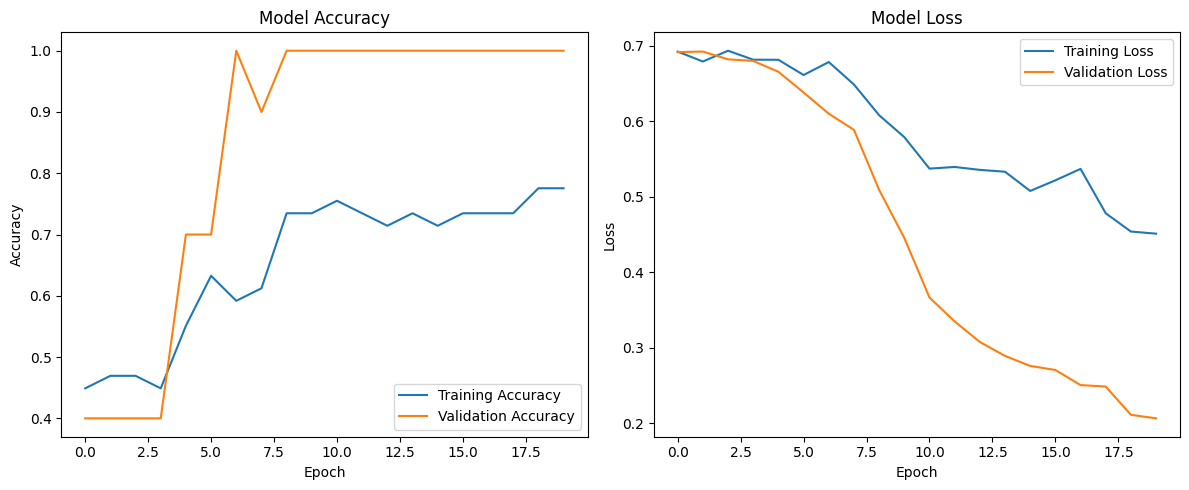

In [48]:

# Cell 19: Plot Accuracy and Loss

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [49]:

# Cell 20: Evaluate Model on Test Data

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fall"],
    zero_division=0
))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))
else:
    print("ROC-AUC cannot be calculated: test set contains only one class.")


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Test Accuracy: 0.5454545454545454

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.17      0.29         6
        Fall       0.50      1.00      0.67         5

    accuracy                           0.55        11
   macro avg       0.75      0.58      0.48        11
weighted avg       0.77      0.55      0.46        11

ROC-AUC Score: 0.6333333333333333


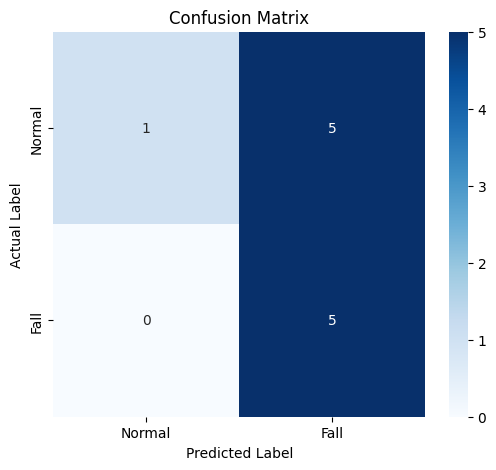

In [50]:

# Cell 21: Display Confusion Matrix

import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fall"],
    yticklabels=["Normal", "Fall"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


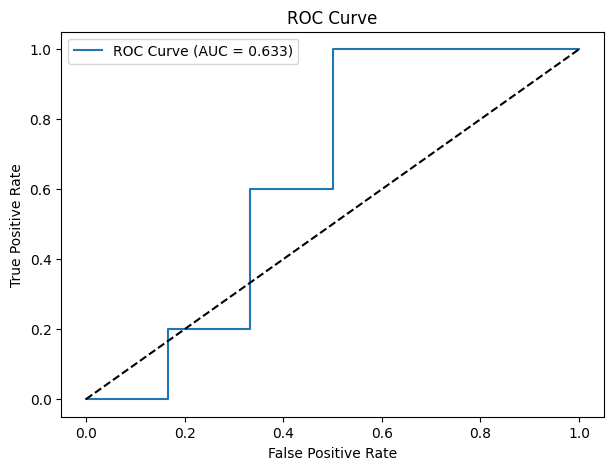

In [51]:

# Cell 22: Plot ROC Curve

from sklearn.metrics import roc_curve, auc

if len(np.unique(y_test)) == 2:
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()
else:
    print("ROC curve requires both classes in the test set.")


In [52]:

# Cell 23: Predict Fall or Normal for One Test Sequence

sample = X_test[0:1]

prediction = model.predict(sample)[0][0]

if prediction >= 0.5:
    print("Prediction: FALL DETECTED")
else:
    print("Prediction: NORMAL ACTIVITY")

print("Fall Probability:", prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step
Prediction: FALL DETECTED
Fall Probability: 0.53919023


In [53]:

# Cell 24: Save Trained Model

model.save("/content/fall_detection_3dcnn.keras")

print("Model saved successfully!")


Model saved successfully!


In [54]:

# Cell 25: Download Saved Model

from google.colab import files

files.download("/content/fall_detection_3dcnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>